# 04 · 전체 ETF 20종의 검정창 일반화와 강건성

**연구 질문.** 03 에서 **실제 ETF 경보를 보지 않고** 정한 W1 의 임계값·적격성·판정을 20종의 자산군·연도에 그대로 적용한다. 그때 평가 가능일과 관측 경보 부담은 어떻게 달라지는가?

이 노트북은 새 우승 창을 찾지 않는다. 실제 ETF 에는 독립적인 분산 변화 정답이 없으므로, 종목별 검출력·거짓양성률·최적 창은 확정하지 않는다.

**입력.** T12 원자료, 00–02 결과, 03 실행 지문이 모두 있어야 시작한다. 03 의 4종을 포함한 20종 모두 같은 기간을 같은 연구 과정에서 이미 관찰한 자료다. 그래서 이 결과는 **독립 외부 검증이 아니다**.

**기간.** 주 기간은 2021–2025 다. 2020 파일럿(학습 이력 1년)과 2026 부분·비블라인드(10/2 까지)는 별도 표와 그림으로 남긴다.

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t13_window_study_v1.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import hashlib  # 파일 SHA256 지문
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import json  # 03→04 인계 파일
import platform  # Python 버전
import time  # 실행 시간 기록

import matplotlib.pyplot as plt  # 그림 기본 설정
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, display  # 표·그림 출력
from matplotlib import font_manager  # 한글 글꼴 등록

# T12 재현 환경과 같은 버전이어야 한다 (user-site 의 다른 numpy/pandas 를 잡으면 여기서 멈춘다).
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scikit-learn": "1.9.1"}  # T12 종결 기준
ACTUAL_ENV = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": metadata.version("scikit-learn")}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패로 처리
assert "site-packages" in np.__file__ and ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = [font_manager.FontProperties(fname=str(FONT_FILE)).get_name(), "DejaVu Sans"]  # 한글 우선·기호 대체
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지

from r2h.window_study.empirical import frozen_root, verify_frozen  # T12 동결 입력 검증
from r2h.window_study.simulation import load_cfg  # W1 동결 설정

CFG = load_cfg(ROOT)  # 동결 설정 configs/t13_window_study_v1.json 읽기
SOURCE = frozen_root(ROOT)  # T12 종결 작업트리 (일별 잔차 cache 위치)
assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
FROZEN = verify_frozen(ROOT, SOURCE, CFG)  # 00·01·02 노트북·원자료 22개·run manifest 해시 대조
CONFIG_SHA = hashlib.sha256((ROOT / "configs/t13_window_study_v1.json").read_bytes()).hexdigest()  # 설정 지문
BASE = ROOT / "research/window_study_w1"  # W1 산출물 폴더
BASE.mkdir(parents=True, exist_ok=True)  # 없으면 만든다
print("작업트리:", ROOT)  # 실행 위치 기록
print("동결 T12:", FROZEN)  # 입력 검증 결과
print("W1 설정 SHA256:", CONFIG_SHA)  # 설정 지문
print("실행 환경:", ACTUAL_ENV, "| 인터프리터:", sys.executable)  # 재현 환경 기록

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1016/R2H_CUSUM_Window_Study
동결 T12: {'run_id': 'b_nb_20261016T181251', 'data_version': '5f20e3e0073b521a', 'notebook_count': 3, 'raw_sha_count': 22, 'daily_ticker_count': 20, 'source_root': '/home/sieg/projects-wsl/hongik_univ_26_2/SA/1016/R2H_T12_Final'}
W1 설정 SHA256: 8489eada913a3e624149f8ce05315d5be4ca1916680c1c51b5afe734a3015681
실행 환경: {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1'} | 인터프리터: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1012_Annual_SVR–GARCH-CUSUM/R2H/.venv/bin/python


## 1. 입력 계약과 통계적 단위

**임계값.** 03 의 `pipeline_garch_annual_max` 는 정책·w 별 합성 GARCH H0 에서 구한 연중 최대 T 의 95% 임계값이다. 원 T12 의 점별 iid 임계값과 섞지 않는다.

**평가일.**
- T12 `rolling_cusum` 으로 연도별 PURE 경로를 다시 계산한다.
- 창별 전체 PURE 와 네 창 공통 `t ≥ 119` 교집합을 모두 기록한다.
- `w=252` 는 242–248 거래일 연도 안에서 PURE 를 만들 수 없어 평가 불가다. 이것을 무경보로 바꾸지 않는다.

경보는 `T_t(w) ≥ c_{policy,w}` 인 관측 사건일 뿐, 참 구조변화가 아니다.

**집계 단위.**
- 일별 경보
- 비경보 5일 간격으로 묶은 **에피소드**. 한 에피소드 안의 여러 경보일은 독립 반복이 아니다.
- ETF×연도
- 노출 그룹×연도. 069500·102110·122630·114800 은 모두 KOSPI200 을 추종하므로 네 개의 독립 시장 노출이 아니다. 그래서 별도 그룹 민감도를 낸다.

나머지 ETF 도 시장 충격을 공유할 수 있다. 그래서 그룹 평균에 단순 독립 신뢰구간을 붙이지 않는다.

In [2]:
# 03 의 full 실행 지문을 검증하고, 그 임계값·판정을 고정 입력으로 읽는다.
from r2h.window_study.empirical import category_exposure, empirical_experiment  # 실측 재계산·종목표

TRANSFER_PATH = BASE / "03_to_04_transfer.json"  # 03 인계 파일
TRANSFER = json.loads(TRANSFER_PATH.read_text(encoding="utf-8"))  # 인계 계약 읽기
assert TRANSFER["mode"] == "FULL_EXECUTED" and TRANSFER["study_id"] == CFG["study_id"]  # smoke 결과 금지
assert TRANSFER["config_sha256"] == CONFIG_SHA and TRANSFER["base_commit"] == CFG["base_t12_commit"]  # 같은 설정·기준 커밋
assert TRANSFER["environment"] == ACTUAL_ENV  # 03 과 같은 실행 환경
for rel, expected in TRANSFER["files_sha256"].items():  # 인계 파일마다
    actual = hashlib.sha256((ROOT / rel).read_bytes()).hexdigest()  # 현재 SHA256
    assert actual == expected, (rel, actual, expected)  # 03 이후 변경 금지
START04 = time.time()  # 04 실행 시간 시작
THRESHOLDS = pd.read_csv(BASE / "results/03_synthetic/pipeline/pipeline_thresholds.csv")  # 03 정책·w 별 연간 임계값
SELECTION03 = pd.read_csv(BASE / "최적창_판정과_보류사유.csv")  # 03 판정표
print("03→04 보정·판정 파일 SHA 검증:", len(TRANSFER["files_sha256"]), "개 PASS")  # 검증 기록
print("사전 적격 w:", TRANSFER["eligible_windows"], "파레토 후보 w:", TRANSFER["pareto_windows"])  # 03 결론
display(SELECTION03)  # 03 판정표 그대로

03→04 보정·판정 파일 SHA 검증: 7 개 PASS
사전 적격 w: [] 파레토 후보 w: []


,w,detector_size_ok,detector_power_delay_ok,pipeline_A_size_ok,pipeline_A_power_delay_ok,eligible,insufficient_precision,failure_reason,pipeline_A_power_lower,detector_min_power_lower,pipeline_A_median_delay,pareto,decision
0,20,True,False,True,False,False,False,검출기 검출/지연; 적합 포함 검출/지연,0.010725,0.021094,24.0,False,비적격
1,30,True,False,True,False,False,False,검출기 검출/지연; 적합 포함 검출/지연,0.034652,0.020266,26.5,False,비적격
2,60,True,False,False,False,False,False,검출기 검출/지연; 적합 포함 귀무 상한; 적합 포함 검출/지연,0.042152,0.049550,16.5,False,비적격
3,120,True,False,True,False,False,False,검출기 검출/지연; 적합 포함 검출/지연,0.057687,0.043375,31.5,False,비적격


In [3]:
# 공식 T11 종목표 순서대로 20종을 읽고, T12 동결 잔차에서 창 경로를 전부 재계산한다.
META = category_exposure(ROOT)  # 코드·이름·자산군·노출 그룹
assert len(META) == 20 and META.ticker.is_unique  # 20종, 중복 없음
REAL04 = empirical_experiment(ROOT, SOURCE, CFG, META.ticker.tolist(), THRESHOLDS, BASE / "results/04_real")  # 03 과 같은 함수·임계값
VALID04, ALARM04 = REAL04["validity.csv"], REAL04["alarm_metrics.csv"]  # 평가 가능일·경보 지표
assert REAL04["daily_cache_qa.csv"].max_abs_pure_T_diff_from_T12_cache.max() < 1e-8  # 재계산 경로 = T12 cache
assert VALID04.query("w == 252").n_pure_valid.eq(0).all()  # w=252 PURE 구조적 불가
print("20종 결과 행수: 평가일", len(VALID04), "경보 표", len(ALARM04), "탐색 후보", len(REAL04["cnn_candidate_intervals.csv"]))  # 행 수 기록
print("T12 cache 대비 PURE T 최대 절대차:", REAL04["daily_cache_qa.csv"].max_abs_pure_T_diff_from_T12_cache.max())  # 직렬화 반올림 수준
display(VALID04.groupby(["year_status", "w", "status"]).agg(ETF_연도_정책=("ticker", "size"), 공통유효일=("n_common_valid", "sum")).reset_index())  # 표 1
display(REAL04["daily_cache_qa.csv"].merge(META[["ticker", "name"]], on="ticker"))  # 종목별 cache 해시·차이

20종 결과 행수: 평가일 2100 경보 표 6720 탐색 후보 142
T12 cache 대비 PURE T 최대 절대차: 1.2167287177788921e-09


,year_status,w,status,ETF_연도_정책,공통유효일
0,PARTIAL_NON_BLIND,20,EVALUABLE,60,3878
1,PARTIAL_NON_BLIND,30,EVALUABLE,60,3878
2,PARTIAL_NON_BLIND,60,EVALUABLE,60,3878
3,PARTIAL_NON_BLIND,120,EVALUABLE,60,3878
4,PARTIAL_NON_BLIND,252,NO_FULL_WINDOW,60,0
5,PILOT_SHORT_HISTORY,20,EVALUABLE,60,7728
6,PILOT_SHORT_HISTORY,30,EVALUABLE,60,7728
7,PILOT_SHORT_HISTORY,60,EVALUABLE,60,7728
8,PILOT_SHORT_HISTORY,120,EVALUABLE,60,7728
9,PILOT_SHORT_HISTORY,252,NO_FULL_WINDOW,60,0


,ticker,daily_sha256,max_abs_pure_T_diff_from_T12_cache,n_daily_rows,name
0,069500,ebd0c99b887b871b67f2e6818f938ed518ea05666880eb...,9.195724e-10,29826,KODEX 200
1,102110,b28a81a0a81fa9e31b8508571e08da936cf8b7b56413e2...,8.989987e-10,29826,TIGER 200
2,229200,4e74ee6fbbb843e2c8e977ad5132581af2e2a2b20dabd2...,1.088578e-09,29826,KODEX 코스닥150
3,122630,5e1416833ac3fb70b8b35057bb001bcf4dc646157c3399...,9.448231e-10,29826,KODEX 레버리지
4,114800,fdeaa6311715572e7577c2e7fe1f46f3626264ffb1d146...,8.494765e-10,29826,KODEX 인버스
5,091230,f2c5ae9286028774180ab34ac6bfb590c3488b065a9a08...,8.865142e-10,29826,TIGER 반도체
6,091170,89156d44645a1201f51fd723525cef8daebba9f5fd19a0...,9.290717e-10,29826,KODEX 은행
7,091180,9fd642fc5a87281b19146c1750310055acf98ff801d502...,9.668570e-10,29826,KODEX 자동차
8,305540,3c70af625571a8f4617246fb3ce90021a20f2f87e18947...,1.018671e-09,29826,TIGER 2차전지테마
9,143860,2d936be4b8435baa66fa3d9614cce4e3da00008940dc4a...,9.129895e-10,29826,TIGER 헬스케어


### 표 1. 계산 가능한 날짜가 먼저다

**세 가지 날짜 수.**
- `n_pure_possible`: 그 연도 안에서 w일을 채울 수 있는 날의 수.
- `n_pure_valid`: 그중 잔차와 정규화가 유한한 날의 수.
- `n_common_valid`: 네 후보 창이 모두 평가 가능한 날의 수.

**기간 제약.** 2020 은 학습 이력이 짧고, 2026 은 10월 2일까지의 부분·비블라인드다. 그래서 주 평균에 넣지 않는다.

**착시 주의.** 평가일이 다른 상태에서 경보 건수만 비교하면, 긴 창이 더 '안전해' 보이는 착시가 생긴다.

**cache 대비 차이.** 최대 절대차는 1e-9 수준이다. 이는 PURE 유효일 전체에서 T12 cache(`%.10g` 직렬화)와 비교한 반올림 차이이며, 계산 차이가 아니다.

In [4]:
# 03 의 4종 행과 04 에서 재계산한 같은 4종 행이 내용 기준으로 같은지 확인한다 (둘 다 디스크 CSV 를 읽어 비교).
keys_valid = ["ticker", "year", "policy", "w"]  # validity 키
keys_alarm = [*keys_valid, "threshold_type", "sample_type"]  # alarm_metrics 키
for name, keys in (("validity.csv", keys_valid), ("alarm_metrics.csv", keys_alarm)):  # 두 표
    old = pd.read_csv(BASE / "results/03_real" / name, dtype={"ticker": str})  # 03 저장본
    new_disk = pd.read_csv(BASE / "results/04_real" / name, dtype={"ticker": str})  # 04 저장본
    sub = new_disk[new_disk.ticker.isin(CFG["representative_tickers"])]  # 04 중 대표 4종
    left = old.sort_values(keys).reset_index(drop=True)  # 키 정렬
    right = sub.sort_values(keys).reset_index(drop=True)  # 키 정렬
    pd.testing.assert_frame_equal(left, right, check_dtype=False, check_exact=False, atol=1e-9, rtol=1e-9)  # 내용 동등
    print("03/04 대표 4종 동등:", name, len(left), "행")  # 확인 기록

03/04 대표 4종 동등: validity.csv 420 행
03/04 대표 4종 동등: alarm_metrics.csv 1344 행


In [5]:
# 핵심 연도·공통 PURE·정책 A 를 임계값 종류별로 요약한다 (분모 = 공통 유효 거래일).
CORE04 = ALARM04.query("year >= 2021 and year <= 2025 and policy == 'A' and sample_type == 'common'")  # 주 분석 범위
SUMMARY04 = CORE04.groupby(["threshold_type", "w"]).agg(ETF_연도=("ticker", "size"), 유효일=("n_valid_days", "sum"), 경보일=("alarm_days", "sum"), 에피소드=("episodes", "sum"), 경보있는_ETF연도=("any_alarm", "sum")).reset_index()  # 임계값·창별 합계
SUMMARY04["252유효일당_에피소드"] = SUMMARY04.에피소드 * 252 / SUMMARY04.유효일  # 관측 경보 강도 (오탐률 아님)
display(SUMMARY04)  # 표 2
period04 = ALARM04.query("policy == 'A' and threshold_type == 'pipeline_garch_annual_max' and sample_type == 'common'").groupby(["year_status", "w"]).agg(ETF_연도=("ticker", "size"), 유효일=("n_valid_days", "sum"), 에피소드=("episodes", "sum"), 경보있는_ETF연도=("any_alarm", "sum")).reset_index()  # 기간 상태별
display(period04)  # 표 2-보조: 2020 파일럿·2026 부분 분리

,threshold_type,w,ETF_연도,유효일,경보일,에피소드,경보있는_ETF연도,252유효일당_에피소드
0,pipeline_garch_annual_max,20,100,12590,2,2,2,0.040032
1,pipeline_garch_annual_max,30,100,12590,28,11,9,0.220175
2,pipeline_garch_annual_max,60,100,12590,103,18,15,0.360286
3,pipeline_garch_annual_max,120,100,12590,149,12,9,0.240191
4,t12_pointwise_iid_insample,20,100,12590,253,119,69,2.381890
5,t12_pointwise_iid_insample,30,100,12590,125,45,34,0.900715
6,t12_pointwise_iid_insample,60,100,12590,125,23,18,0.460365
7,t12_pointwise_iid_insample,120,100,12590,197,13,9,0.260207


,year_status,w,ETF_연도,유효일,에피소드,경보있는_ETF연도
0,PARTIAL_NON_BLIND,20,20,1300,0,0
1,PARTIAL_NON_BLIND,30,20,1300,0,0
2,PARTIAL_NON_BLIND,60,20,1300,0,0
3,PARTIAL_NON_BLIND,120,20,1300,1,1
4,PILOT_SHORT_HISTORY,20,20,2580,0,0
5,PILOT_SHORT_HISTORY,30,20,2580,5,4
6,PILOT_SHORT_HISTORY,60,20,2580,12,11
7,PILOT_SHORT_HISTORY,120,20,2580,23,16
8,PRIMARY,20,100,12590,2,2
9,PRIMARY,30,100,12590,11,9


In [6]:
# 2021–2025 '경보 있는 ETF·연도' 관측 비율을 같은 임계값의 합성 GARCH 귀무 기대(03 정책 A)와 나란히 둔다.
null_a = pd.read_csv(BASE / "results/03_synthetic/pipeline/pipeline_summary.csv").query("stage == 'H0' and policy == 'A'")  # 03 귀무 평가
obs = CORE04.query("threshold_type == 'pipeline_garch_annual_max'").groupby("w").any_alarm.agg(관측_비율="mean", ETF_연도="size")  # 100 ETF·연도
COMPARE = obs.join(null_a.set_index("w")[["any_alarm", "any_alarm_ci_low", "any_alarm_ci_high"]].rename(columns={"any_alarm": "귀무_기대", "any_alarm_ci_low": "귀무_하한", "any_alarm_ci_high": "귀무_상한"}))  # 비교표
COMPARE["관측/귀무"] = COMPARE.관측_비율 / COMPARE.귀무_기대  # 배율 (독립 시행 가정 없이 기술만)
display(COMPARE.round(3))  # 표 2-비교

,관측_비율,ETF_연도,귀무_기대,귀무_하한,귀무_상한,관측/귀무
w,,,,,,
20,0.02,100,0.035,0.017,0.070,0.571
30,0.09,100,0.045,0.024,0.083,2.000
60,0.15,100,0.070,0.042,0.114,2.143
120,0.09,100,0.055,0.031,0.096,1.636


### 표 2. 경보 부담과 해석의 경계

**분모.** 각 창·임계값 조건에서의 `ETF×연도` 와 **공통 유효 거래일**이다.

**`252유효일당_에피소드`.** 관측된 경보의 강도다. 연간 거짓 경보 확률이 아니다.

**두 임계값의 차이.** 점별 T12 임계값과 연중 보정 임계값이 다른 것은 귀무와 보정 단위의 차이다. 실제 ETF 에는 독립 변화 정답이 없다. 따라서 어느 임계값을 쓰든, 경보 건수가 적다는 것이 정확도가 높다는 증거가 되지 않는다.

**보조 표.** 2020·2026 을 따로 둔 것은 비블라인드·기간 제약을 숨기지 않기 위해서다.

**귀무 기대와의 비교.** 연중 최대 임계값 아래에서는, 합성 GARCH 귀무가 맞을 때 기대되는 '경보 있는 ETF·연도' 비율이 03 표 2 의 정책 A `any_alarm`(0.035–0.07) 이다. 실측 비율이 이보다 크면, 다음 셋 중 하나 이상이다. 지금 자료로는 이 셋을 구별할 수 없다.
- 귀무 모형이 시장과 맞지 않는다.
- 실제로 분산 변화가 있다.
- 노출이 중복된 종목들이 함께 경보를 냈다.

In [7]:
# 자산군 평균(ETF 등가중)과 사전 고정 노출 그룹 등가중 평균을 따로 계산한다.
group_rows = CORE04.query("threshold_type == 'pipeline_garch_annual_max'").merge(META[["ticker", "category", "exposure_group"]], on="ticker", validate="many_to_one")  # 연간 임계값 행 + 분류
ASSET = group_rows.groupby(["category", "w"]).agg(ETF_수=("ticker", "nunique"), ETF_연도=("ticker", "size"), 경보있는_ETF연도=("any_alarm", "sum"), 평균_에피소드_252일=("episodes_per_252_valid_days", "mean"), 평균_경보일=("alarm_days", "mean")).reset_index()  # 자산군별
EXPOSURE = group_rows.groupby(["exposure_group", "year", "w"]).episodes_per_252_valid_days.mean().reset_index()  # 노출 그룹×연도 평균
EXPOSURE_SUMMARY = EXPOSURE.groupby("w").episodes_per_252_valid_days.agg(["mean", "min", "max", "count"]).reset_index()  # 그룹 등가중 요약
ETF_EQUAL = group_rows.groupby("w").episodes_per_252_valid_days.mean().rename("ETF_등가중_평균").reset_index()  # 비교용 ETF 등가중
SPLIT = group_rows.assign(구분=np.where(group_rows.ticker.isin(CFG["representative_tickers"]), "03의 4종", "추가 16종")).groupby(["구분", "w"]).agg(ETF_연도=("ticker", "size"), 경보있는_ETF연도=("any_alarm", "sum"), 평균_에피소드_252일=("episodes_per_252_valid_days", "mean")).reset_index()  # 4종 대 16종
display(ASSET)  # 표 3
display(EXPOSURE_SUMMARY.merge(ETF_EQUAL, on="w"))  # 표 4: 그룹 등가중 대 ETF 등가중
display(SPLIT)  # 표 5
ASSET.to_csv(BASE / "results/04_real/asset_category_summary.csv", index=False)  # 산출 저장
EXPOSURE_SUMMARY.to_csv(BASE / "results/04_real/exposure_equal_summary.csv", index=False)  # 산출 저장
SPLIT.to_csv(BASE / "results/04_real/representative_vs_16.csv", index=False)  # 산출 저장

,category,w,ETF_수,ETF_연도,경보있는_ETF연도,평균_에피소드_252일,평균_경보일
0,broad_market,20,6,30,2,0.132316,0.066667
1,broad_market,30,6,30,1,0.134400,0.366667
2,broad_market,60,6,30,7,0.597558,1.433333
3,broad_market,120,6,30,4,0.337194,2.533333
4,commodity,20,2,10,0,0.000000,0.000000
5,commodity,30,2,10,2,0.395349,0.800000
6,commodity,60,2,10,3,0.792298,3.300000
7,commodity,120,2,10,2,0.601600,3.200000
8,currency,20,1,5,0,0.000000,0.000000
9,currency,30,1,5,2,1.222712,0.600000


,w,mean,min,max,count,ETF_등가중_평균
0,20,0.046700,0.0,2.016000,85,0.039695
1,30,0.260377,0.0,4.097561,85,0.221321
2,60,0.298728,0.0,4.032000,85,0.358352
3,120,0.267083,0.0,4.097561,85,0.241671


,구분,w,ETF_연도,경보있는_ETF연도,평균_에피소드_252일
0,03의 4종,20,20,0,0.000000
1,03의 4종,30,20,0,0.000000
2,03의 4종,60,20,4,0.494623
3,03의 4종,120,20,1,0.097674
4,추가 16종,20,80,2,0.049619
5,추가 16종,30,80,9,0.276651
6,추가 16종,60,80,11,0.324284
7,추가 16종,120,80,8,0.277671


In [8]:
# 같은 KOSPI200 노출 4종의 경보 연도가 얼마나 겹치는지 센다 (독립 시행이 아님을 보이는 기술 통계).
kospi = group_rows[group_rows.exposure_group.eq("KOSPI200_동일노출")]  # 동일 노출 4종의 행
overlap = kospi.groupby(["year", "w"]).any_alarm.agg(경보_종목수="sum", 종목수="size").reset_index()  # 연도·창별 경보 종목 수
display(overlap.query("경보_종목수 > 0"))  # 경보가 있던 연도·창만

,year,w,경보_종목수,종목수
2,2021,60,2,4
3,2021,120,1,4
14,2024,60,4,4


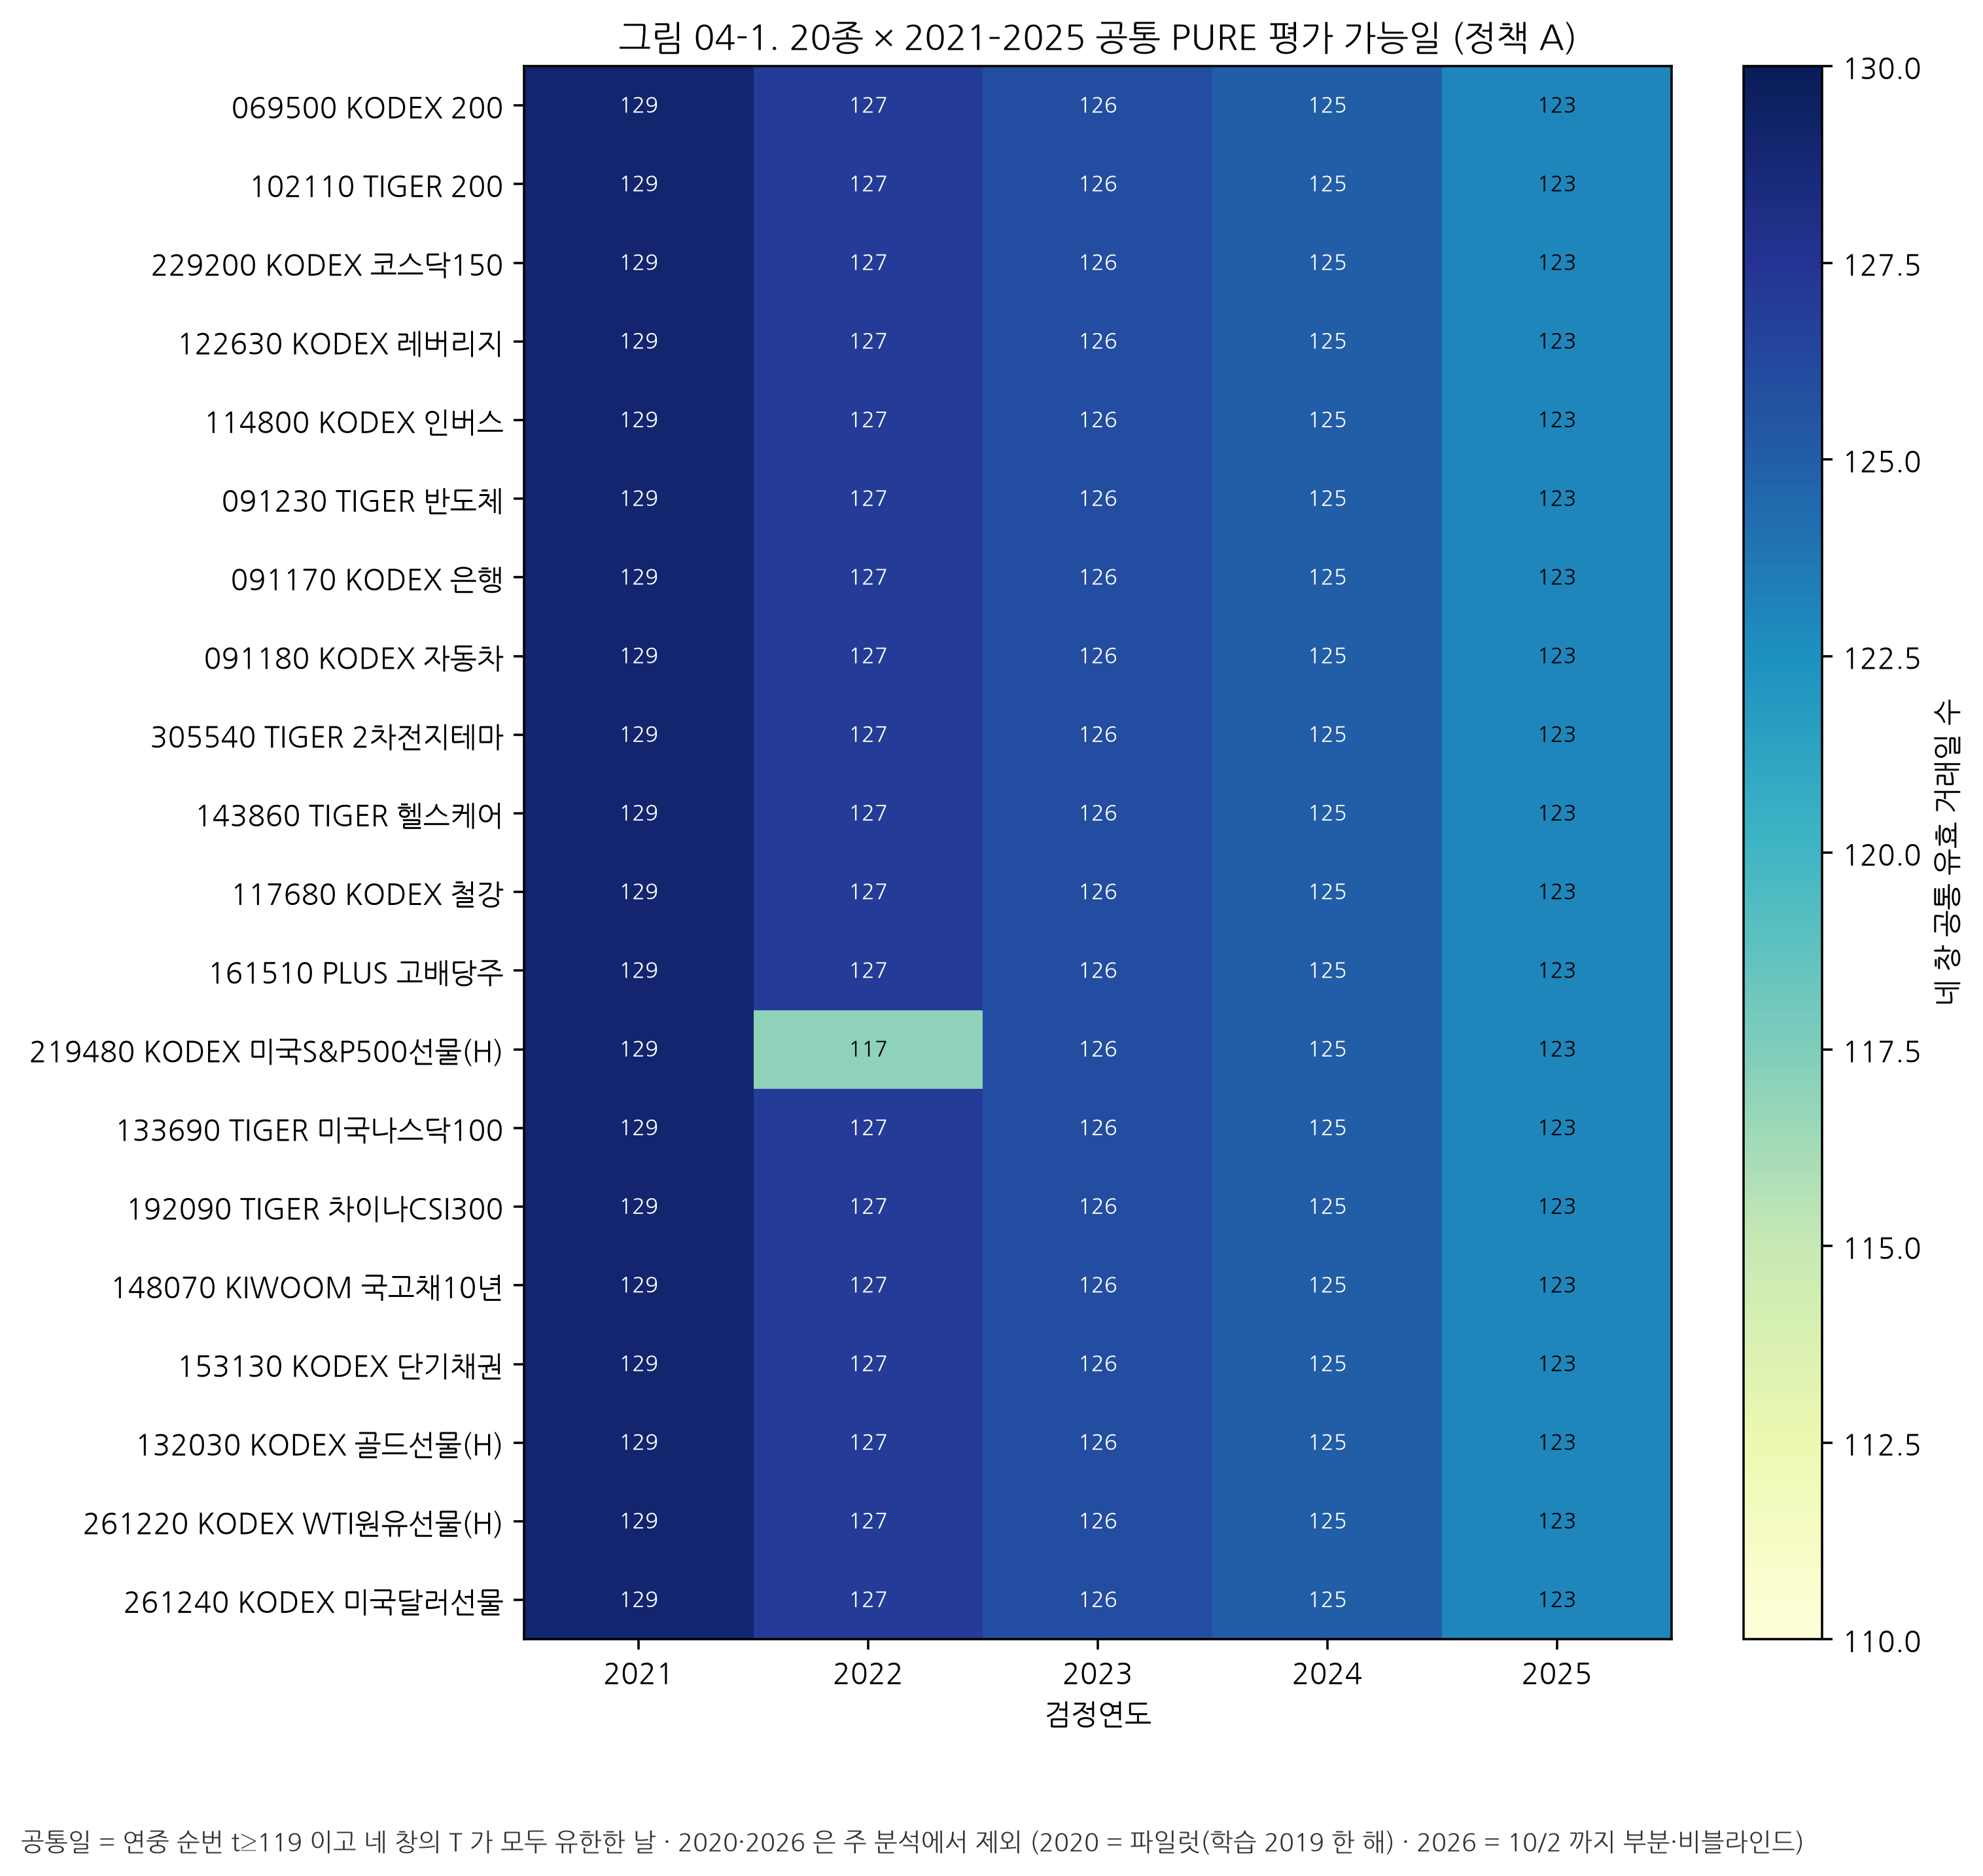

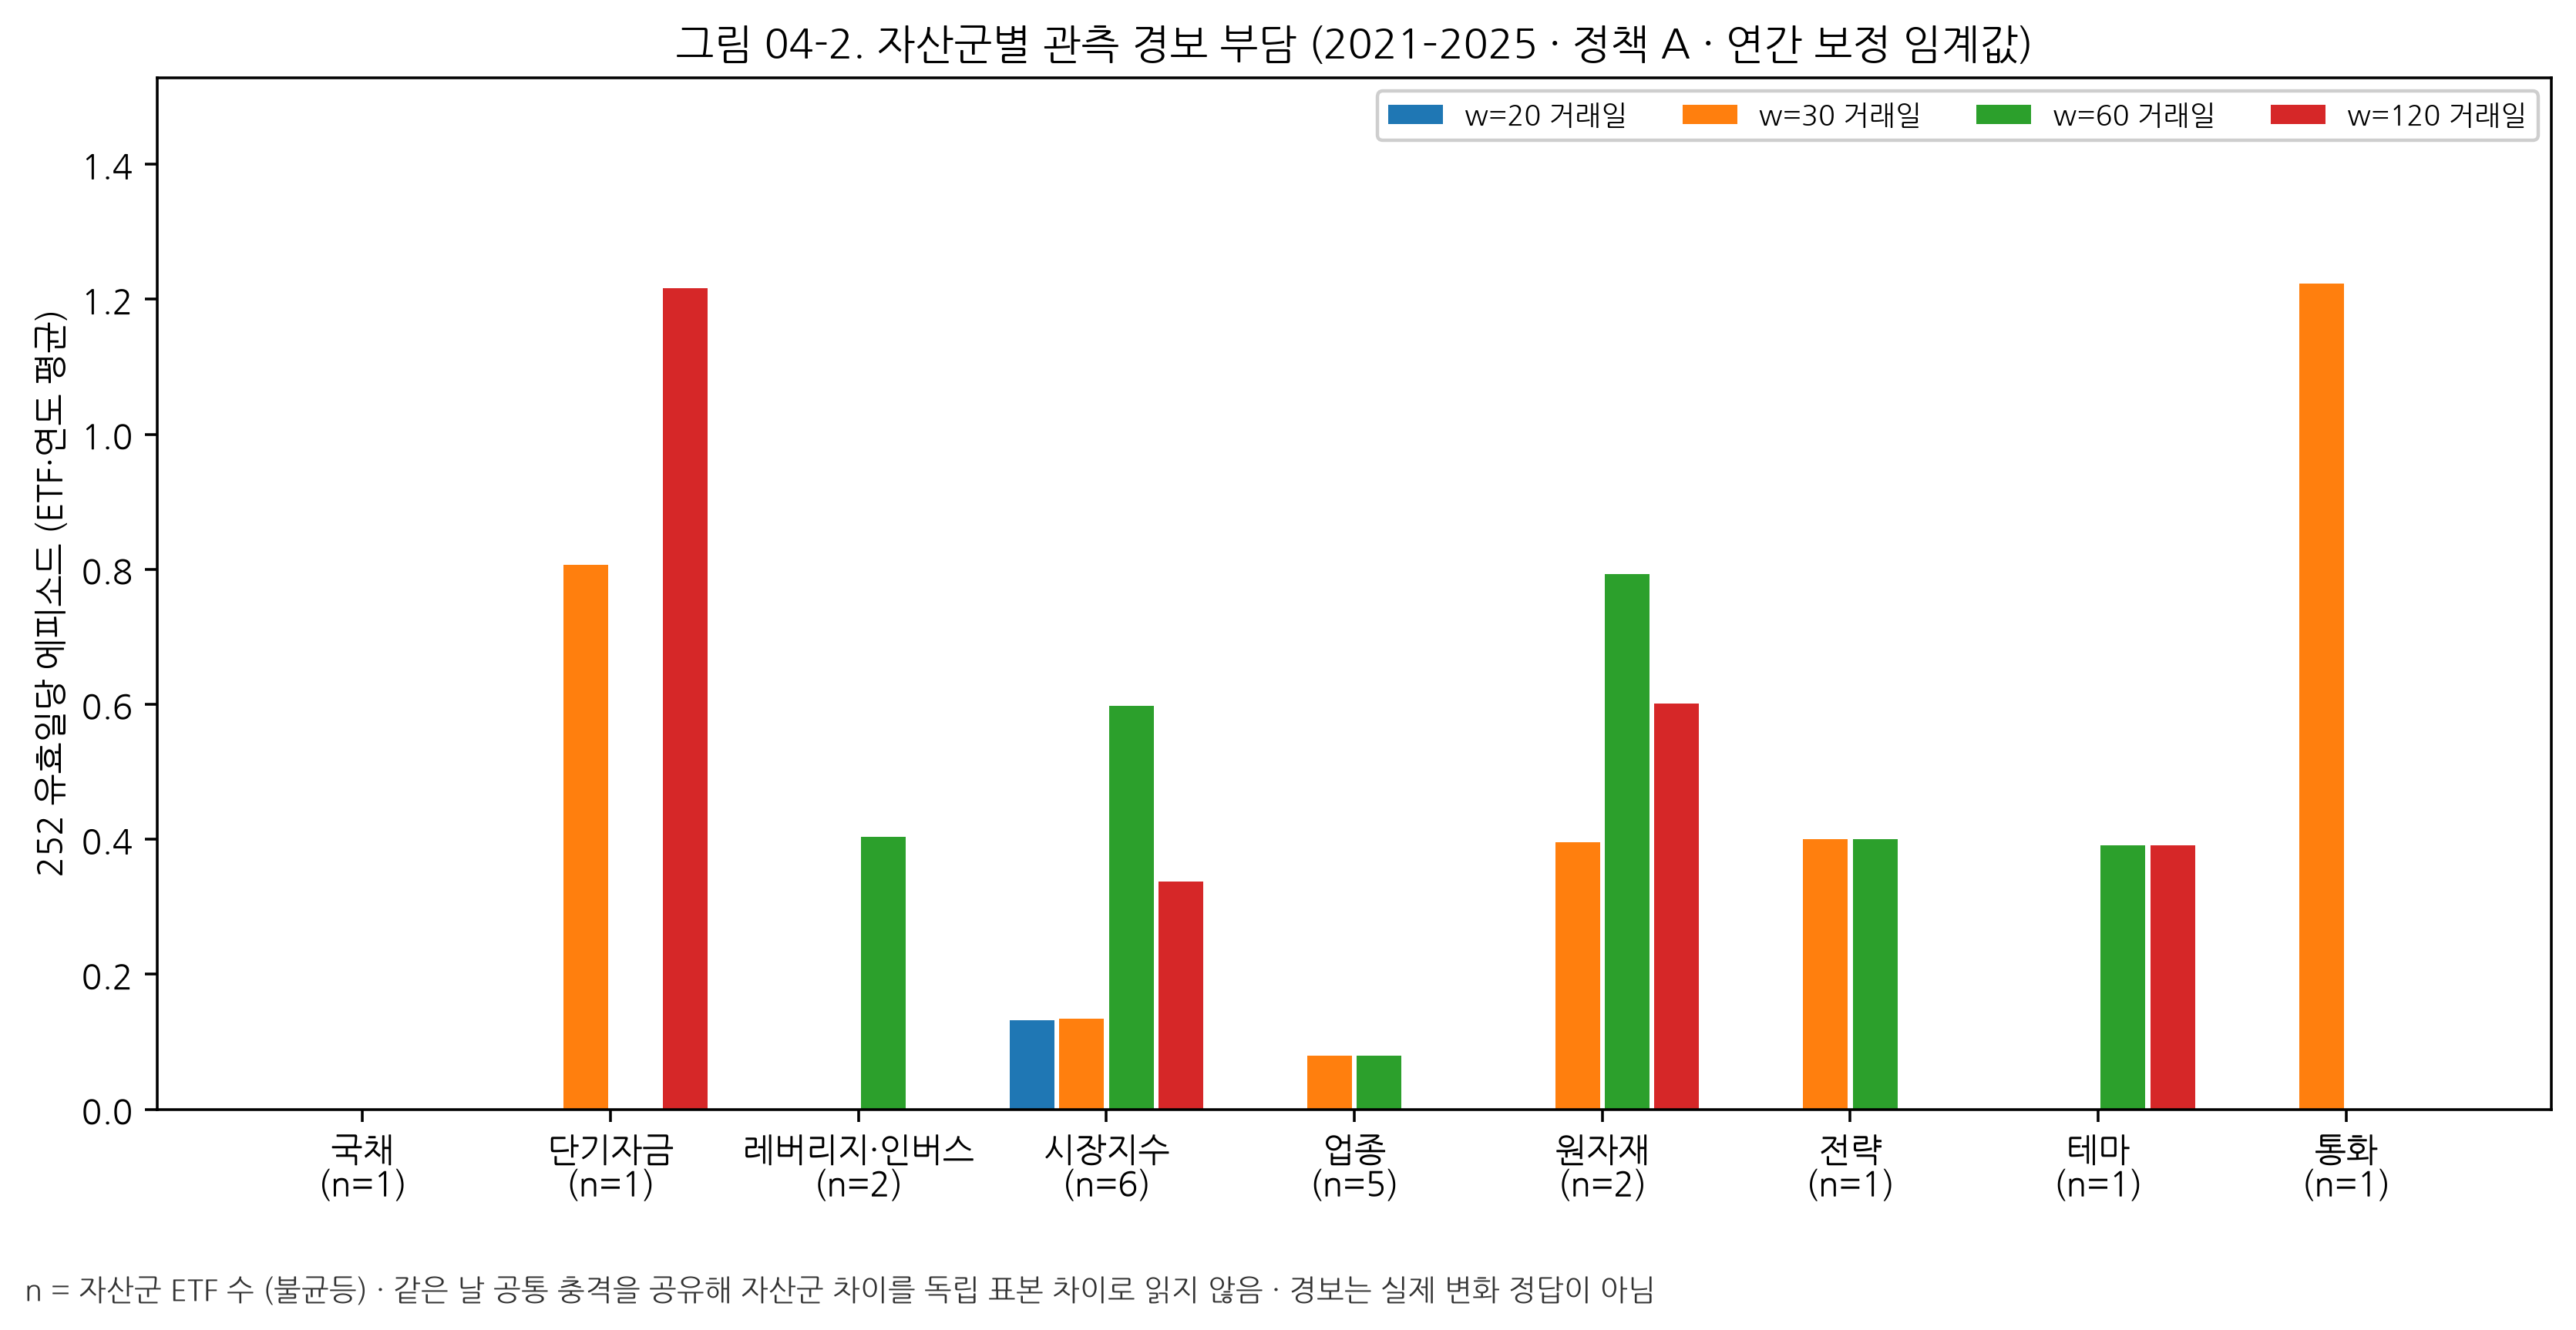

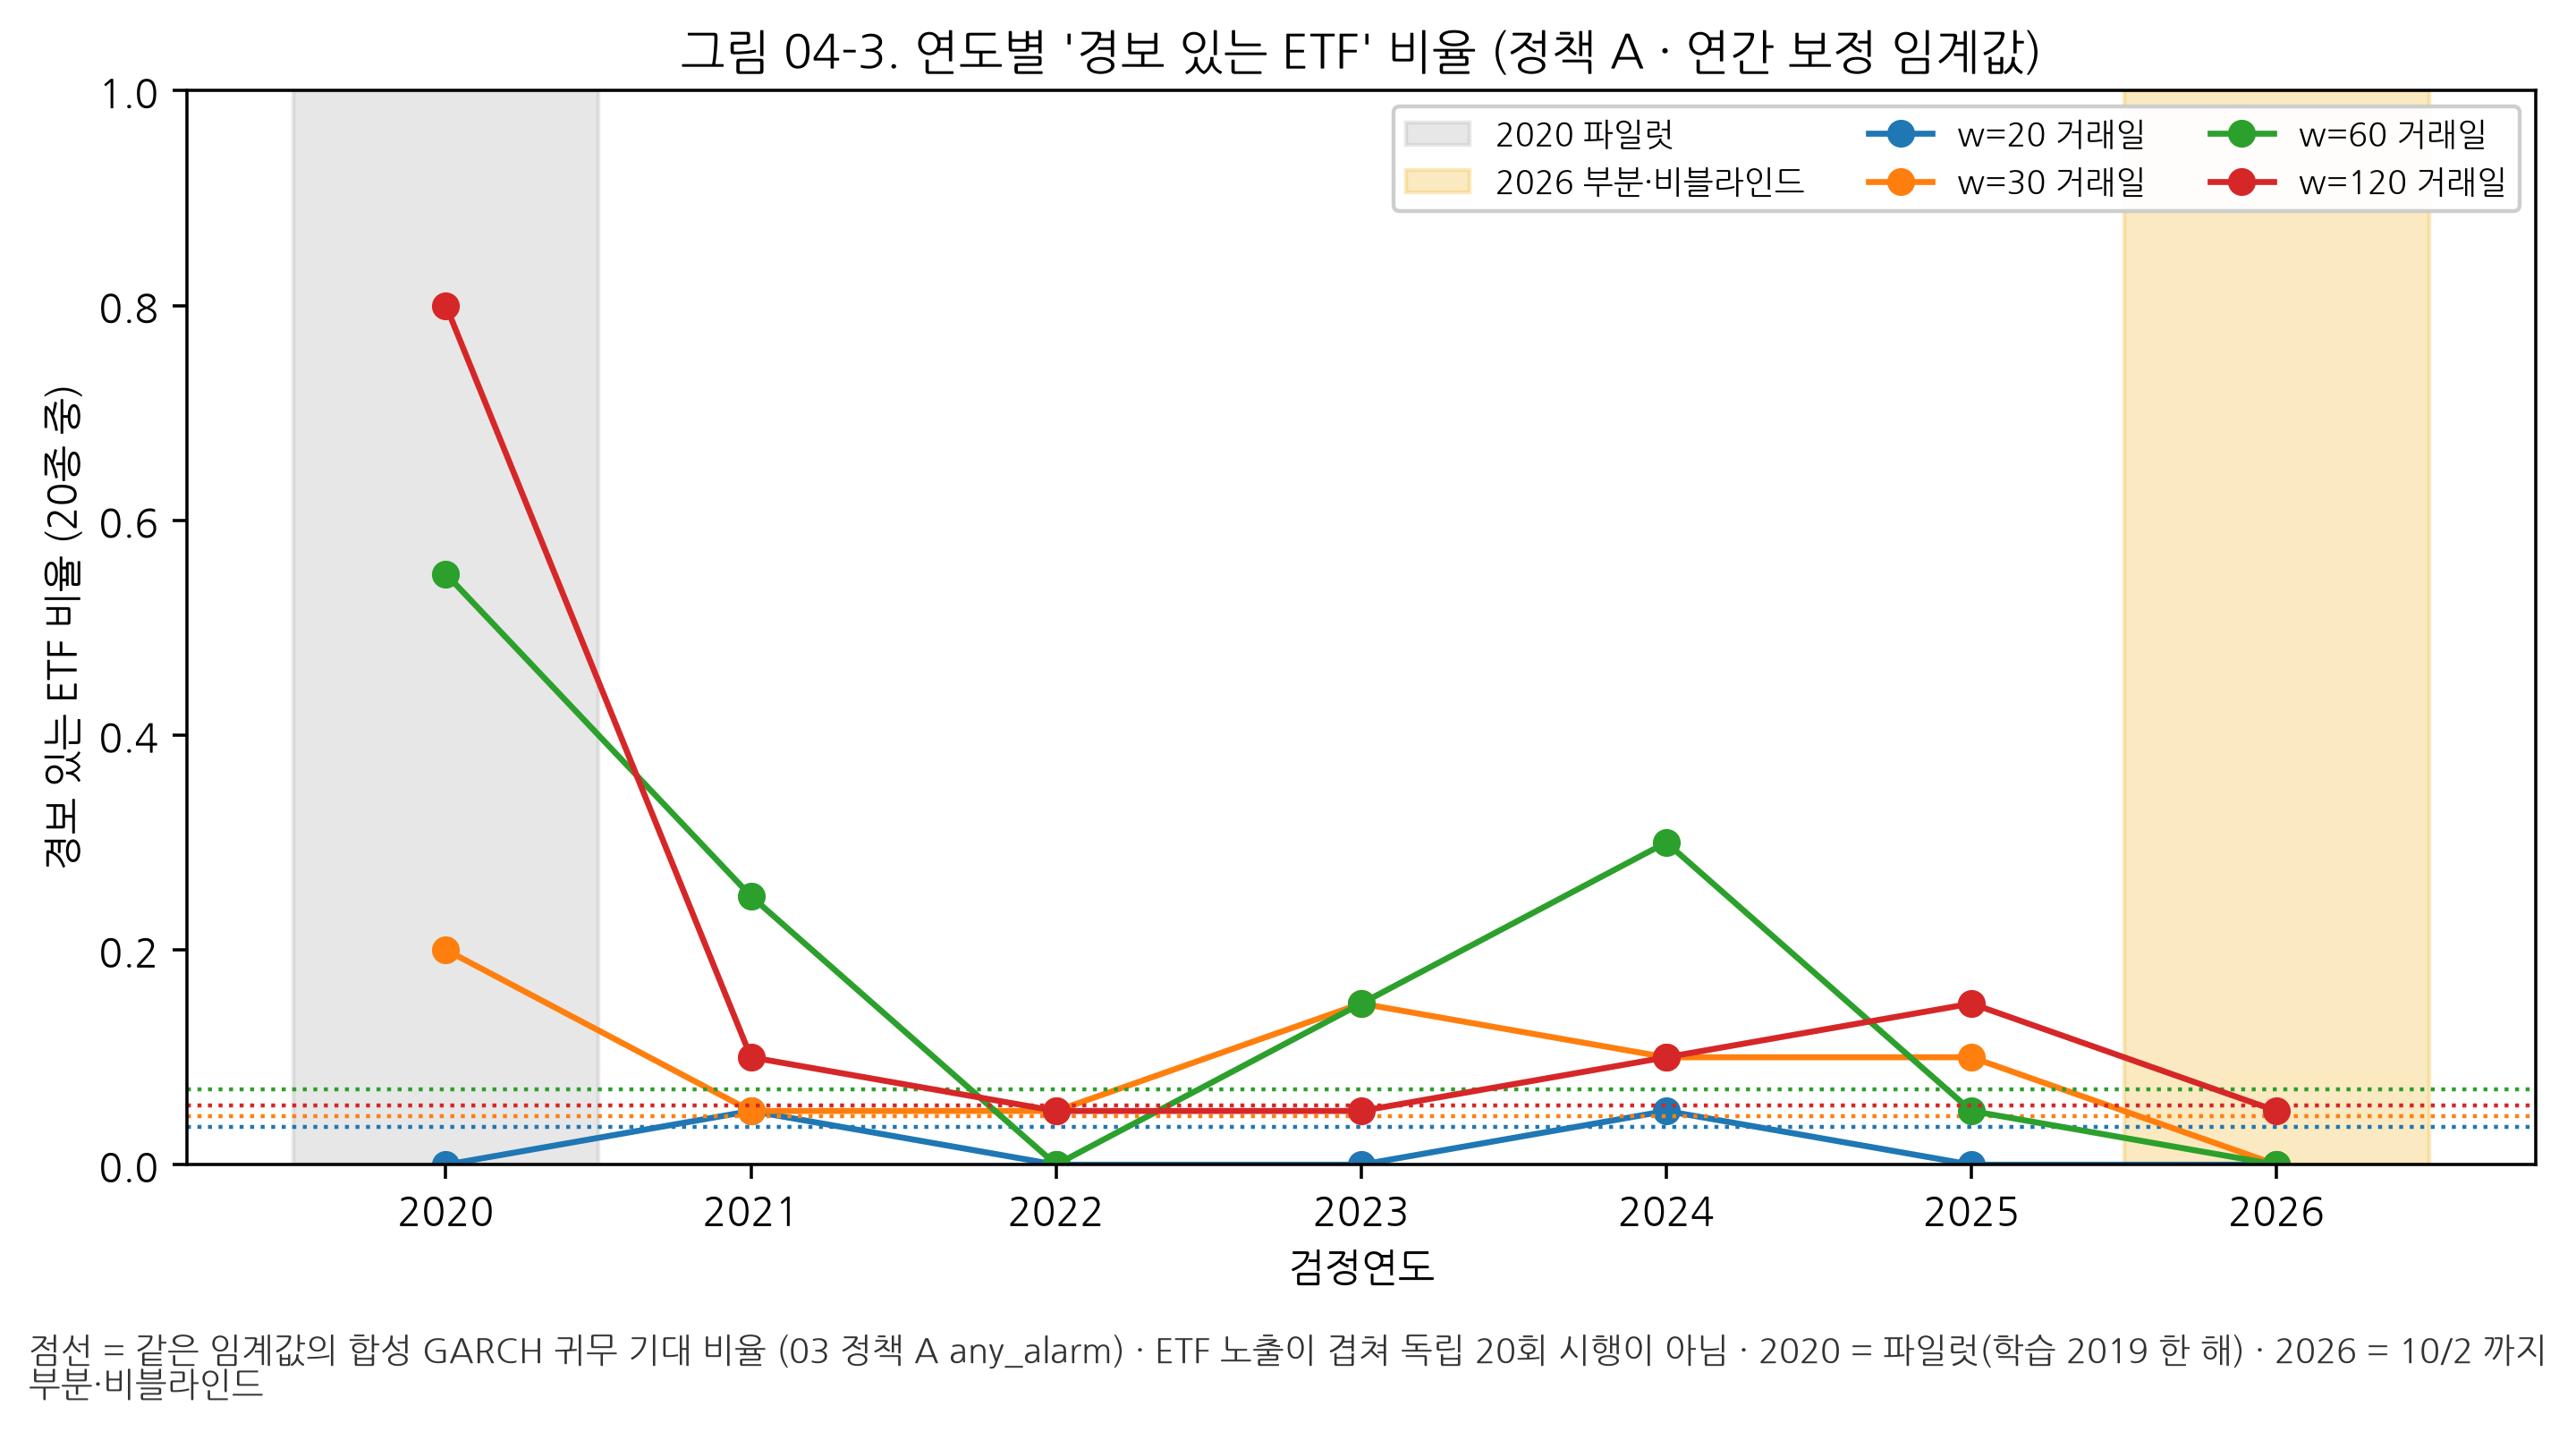

,그림,캡션,자료
0,fig04_01_공통일_히트맵,20 ETF × 2021–2025 정책 A. 네 후보 창(20/30/60/120)의...,validity.csv
1,fig04_02_자산군_경보,20 ETF × 2021–2025·정책 A·공통 PURE. 자산군 평균 에피소드; ...,alarm_metrics.csv + reference_close_sha256.csv
2,fig04_03_연도별_경보비율,20 ETF × 2020–2026·정책 A·공통 PURE. 연도별 경보 있는 ETF...,alarm_metrics.csv


In [9]:
# 20종 × 연도의 평가일·경보 부담을 한국어 그림(PNG 320dpi + SVG)으로 보존한다.
from r2h.window_study.figures import empirical_figures  # W1 그림 함수

FIG04 = BASE / "figures/04"  # 04 그림 폴더
NULL_A = pd.read_csv(BASE / "results/03_synthetic/pipeline/pipeline_summary.csv").query("stage == 'H0' and policy == 'A'").set_index("w").any_alarm.to_dict()  # 03 합성 귀무 기대 비율
INDEX04 = empirical_figures(VALID04, ALARM04, META, FIG04, NULL_A)  # 그림 04-1~04-3
INDEX04.to_csv(FIG04 / "figure_index.csv", index=False)  # 그림 색인·해시
for item in INDEX04.itertuples(index=False):  # 그림마다
    display(Image(filename=item.PNG))  # 본문에 표시
display(INDEX04[["그림", "캡션", "자료"]])  # 그림 번호·캡션·근거 표

## 2. 그림 해석과 일반화라고 부를 수 있는 범위

**그림 04-1.** 20종 × 2021–2025 의 공통 유효일(정책 A)을 보여 준다. 각 칸이 비교 가능한 범위의 크기이며, 검정력이 아니다.

**그림 04-2.** 자산군별 관측 경보 부담이다.
- 가로축의 자산군마다 ETF 수가 다르다 (막대 위 `n=`).
- 세로축 단위는 252 유효일당 에피소드다.
- 범주 이름은 공식 종목표를 따른다. 같은 날의 공통 충격을 공유하므로, 범주 간 차이를 독립 표본의 차이로 읽지 않는다.

**그림 04-3.** 2020 파일럿과 2026 부분·비블라인드를 음영으로 구분해, 연도별 '경보 있는 ETF' 비율을 보인다. 점선은 같은 임계값에서 합성 GARCH 귀무가 맞을 때의 기대 비율이다. 연도 차이를 시장 구조 때문이라고 귀속하지 않는다. 학습 이력 길이, 평가일 수, 비블라인드 여부가 연도마다 함께 다르기 때문이다 (T12 감사 Q9).

**표 4 (노출 그룹).** KOSPI200 중복 네 상품을 그룹 하나로 묶은 표와 ETF 등가중 표가 다르다면, 그것은 독립 표본 가정이 취약하다는 **민감도** 정보다. 어느 쪽이 참값이라는 증명이 아니다.

**표 5 (4종 대 16종).** 같은 기간에서 4종과 16종의 차이를 비교한 것이다. 선정 이후·비블라인드 관찰이므로 외부 검정을 통과했다는 뜻이 아니다.

**03 이 '최적창 없음' 이므로**, 04 는 새로운 우승 창을 만들지 않는다. 특정 자산군에서 경보가 적거나 많아도, 그 원인을 다음 넷 가운데 하나로 분리하지 못한다.
- 귀무 모형 부적합
- 실제 분산 변화
- 잔차 정책
- 노출 중복

**CNN 인계.** CNN 입력으로는 `alarm_at`(사용 가능 시점), `estimated_change_at`(사후 위치), `window_start/end`, 정책, w, 임계값을 **후보 메타데이터로만** 넘긴다. 이 후보 구간은 구조변화나 급등의 정답이 아니다. 같은 경보가 정책·창별로 여러 번 나타나므로, 142행이 독립된 142개 사건도 아니다.

In [10]:
# CNN 후보 구간의 중복 구조를 센다: 같은 ETF·연도에 여러 정책·창이 겹친다.
cand04 = REAL04["cnn_candidate_intervals.csv"]  # 20종 후보 구간
print("후보 행:", len(cand04), "| 고유 ETF·연도:", cand04[["ticker", "year"]].drop_duplicates().shape[0], "| 고유 ETF·첫경보일:", cand04[["ticker", "alarm_at"]].drop_duplicates().shape[0])  # 중복 정도
display(cand04.groupby(["policy", "w"]).size().unstack("w", fill_value=0))  # 정책×창별 후보 수

후보 행: 142 | 고유 ETF·연도: 53 | 고유 ETF·첫경보일: 131


w,20,30,60,120
policy,,,,
A,2,16,30,36
B,7,9,6,12
base,5,5,1,13


In [11]:
# 실행·출처 지문과 최종 W1 결론을 저장한다. 원자료나 일별 잔차는 Git 에 넣지 않는다.
source_files04 = [BASE / "results/04_real" / p for p in ("validity.csv", "alarm_metrics.csv", "cnn_candidate_intervals.csv", "daily_cache_qa.csv", "asset_category_summary.csv", "exposure_equal_summary.csv", "representative_vs_16.csv")]  # 04 산출 7개
SHA04 = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files04}  # 파일별 SHA256
RELEASE04 = {"study_id": CFG["study_id"], "mode": "FULL_EXECUTED", "config_sha256": CONFIG_SHA, "input_03_transfer_sha256": hashlib.sha256(TRANSFER_PATH.read_bytes()).hexdigest(), "base_t12": FROZEN, "environment": ACTUAL_ENV, "files_sha256": SHA04, "eligible_windows": TRANSFER["eligible_windows"], "pareto_windows": TRANSFER["pareto_windows"], "execution_seconds": round(time.time() - START04, 2)}  # 릴리스 지문
(BASE / "04_release_manifest.json").write_text(json.dumps(RELEASE04, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")  # 저장
print("04 full 완료:", RELEASE04["execution_seconds"], "초; 파일 SHA", len(SHA04), "개")  # 실행 기록
print("결론: W1 최적창", "없음" if not RELEASE04["pareto_windows"] else RELEASE04["pareto_windows"])  # 03 결론 승계
display(pd.DataFrame([{"파일": k, "SHA256": v} for k, v in SHA04.items()]))  # 지문 표

04 full 완료: 5.96 초; 파일 SHA 7 개
결론: W1 최적창 없음


,파일,SHA256
0,research/window_study_w1/results/04_real/valid...,6b4cc3f2d4ec05fd6819aff907fec592b74e90396bc7b8...
1,research/window_study_w1/results/04_real/alarm...,b2e75bca1317cd7856abd12c843fa3504fd5325228e86f...
2,research/window_study_w1/results/04_real/cnn_c...,34d896be516e8f6999c42709ff98f827180a546708f85d...
3,research/window_study_w1/results/04_real/daily...,f8bc2e3df04d7b172652fa741a6e0fd8c2e984629ed63f...
4,research/window_study_w1/results/04_real/asset...,5b9439c48c7aed3e6b7a64f7f648cd5be023b9a6691c74...
5,research/window_study_w1/results/04_real/expos...,bf18a7d31986650806ebe4f5472465e0d5b1d0e7c92886...
6,research/window_study_w1/results/04_real/repre...,e43a5e884079f46c301954a05bc5a5139eda066e464037...


## 3. 종결 답변

**계산으로 확인한 사실.**
- 03 의 적격 판정(0/4)과 임계값을 바꾸지 않고 20종 × 2020–2026 × A/B/base 에 적용했다.
- 평가 가능일, 경보일, 에피소드, 후보 구간을 재계산했다.
- 대표 4종의 03·04 결과는 같다.
- `w=252` 는 PURE 평가 불가다.

**가정 아래에서만 가능한 해석.**
- 합성 GARCH 귀무를 받아들이면, 실측의 '경보 있는 ETF·연도' 비율을 귀무 기대(0.035–0.07)와 비교할 수 있다.
- 다만 ETF 사이 노출이 겹치고 공통 충격이 있어, 이 비율에 독립 이항 신뢰구간을 붙일 수 없다.

**현재 자료로는 판단할 수 없는 주장.**
- 경보가 진짜 변화라는 주장.
- 특정 창이나 자산군에서 '더 좋은 탐지기' 가 있다는 주장.
- 가격 급등 탐지 성능.
- 2026 에서의 독립 검증.

**다음 연구의 전제.**
- 외부 가격 급등 시작 라벨과 구조변화 라벨을 구별해 수집한다.
- 시차, 오탐 비용, 블라인드 자산·기간을 사전에 고정하고 온라인으로 평가한다.
- 10/19 캡스톤의 20거래일 단순 탐지 baseline 은 이 사후 분산 검정과 다른 과제다.

**비교 불가.** T11 70:30 은 T12 연간과 학습 시점·검정 단위가 달라, 기각 건수로 성능을 비교할 수 없다.